# Thiết lập môi trường, Seed và các hằng số đối chứng


In [ ]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.models import EfficientNet_B0_Weights

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
IMAGE_SIZE = 224
NUM_CLASSES = 100
EPOCHS_SCRATCH = 5
EPOCHS_PROBE = 25
EPOCHS_PARTIAL = 5
EPOCHS_FULL = 5
PATIENCE = 4
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./bai6_aircraft_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Chưa bật GPU: chọn Runtime -> Change runtime type -> T4 GPU."
DEVICE = torch.device("cuda:0")
WEIGHTS = EfficientNet_B0_Weights.IMAGENET1K_V1


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("GPU:", torch.cuda.get_device_name(0), "| Thiết bị:", DEVICE)
print("Torch:", torch.__version__, "| Seed:", SEED)

GPU: Tesla T4 | Thiết bị: cuda:0
Torch: 2.14.1+cu130 | Seed: 42


# Phân tích bài toán Transfer Learning trên FGVC-Aircraft

### 1. Phân tích bài toán Transfer Learning trên FGVC-Aircraft
* **Source domain & task:** Ảnh màu tự nhiên và bài toán phân loại 1.000 lớp đối tượng của ImageNet-1K.
* **Target domain & task:** 10.000 ảnh máy bay thuộc 100 biến thể (`variant`) khác nhau trong FGVC-Aircraft (3.334 train, 3.333 validation, 3.333 test).
* **Backbone & Head:** Sử dụng `EfficientNet-B0` trích xuất đặc trưng 1.280 chiều (`model.features` + `model.avgpool`) và thay lớp đầu ra thành `Linear(1280, 100)`.
* **Domain shift & Negative transfer:** Các biến thể máy bay cùng dòng có hình dáng tổng thể gần giống nhau, đồng thời cùng một mẫu máy bay lại mang màu sơn (livery) khác nhau tùy hãng hàng không. Nếu đóng băng hoàn toàn backbone, các đặc trưng màu sắc của ImageNet có thể gây nhiễu cho việc phân biệt cấu trúc hình học của máy bay.
* **Tiền xử lý đặc thù:** Cắt bỏ dải thông tin bản quyền cao 20 pixel ở cạnh dưới cùng của toàn bộ ảnh gốc trước khi biến đổi kích thước theo chuẩn bộ dữ liệu FGVC-Aircraft.

# Tiền xử lý chuẩn ImageNet, tải FGVC-Aircraft & trực quan hóa mẫu

Train: 3334 | Validation: 3333 | Số lớp: 100
Một batch: (32, 3, 224, 224) | Nhãn: (32,)


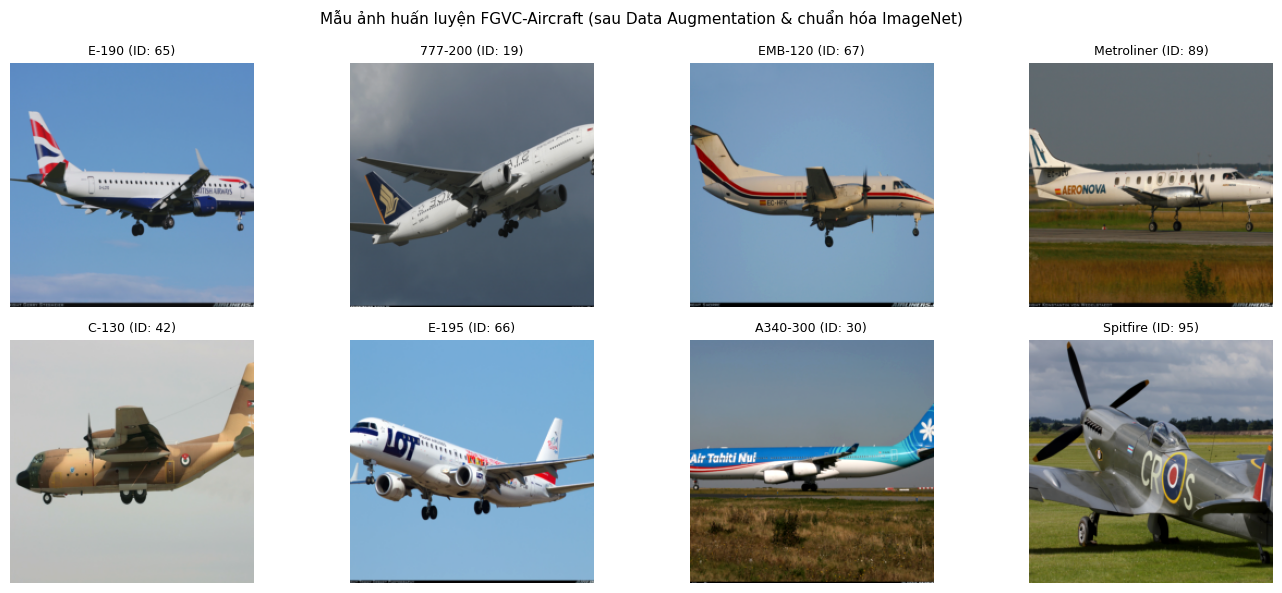

In [ ]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = WEIGHTS.transforms()  # Resize 256 -> CenterCrop 224 -> ToTensor -> Normalize

aircraft_train = datasets.FGVCAircraft(
    DATA_DIR, split="train", annotation_level="variant", download=True, transform=train_transform
)
aircraft_train_clean = datasets.FGVCAircraft(
    DATA_DIR, split="train", annotation_level="variant", download=False, transform=eval_transform
)
aircraft_val = datasets.FGVCAircraft(
    DATA_DIR, split="val", annotation_level="variant", download=False, transform=eval_transform
)

CLASS_NAMES = aircraft_train.classes
assert len(CLASS_NAMES) == NUM_CLASSES

train_loader = DataLoader(
    aircraft_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True
)
train_clean_loader = DataLoader(
    aircraft_train_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    aircraft_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True
)

print(f"Train: {len(aircraft_train)} | Validation: {len(aircraft_val)} | Số lớp: {NUM_CLASSES}")
sample_images, sample_labels = next(iter(train_loader))
print("Một batch:", tuple(sample_images.shape), "| Nhãn:", tuple(sample_labels.shape))
assert sample_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

# Trực quan hóa 8 ảnh mẫu từ tập train
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
mean_t = torch.tensor(MEAN).view(3, 1, 1)
std_t = torch.tensor(STD).view(3, 1, 1)

for idx, ax in enumerate(axes.flat):
    img = (sample_images[idx] * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(f"{CLASS_NAMES[sample_labels[idx]]} (ID: {sample_labels[idx].item()})", fontsize=9)
    ax.axis("off")

plt.suptitle("Mẫu ảnh huấn luyện FGVC-Aircraft (sau Data Augmentation & chuẩn hóa ImageNet)", fontsize=11)
plt.tight_layout()
plt.show()

# Hàm xây dựng mô hình EfficientNet-B0, quản lý BatchNorm & vòng lặp huấn luyện/đánh giá

In [ ]:
def build_efficientnet_b0(mode: str = "full", num_classes: int = NUM_CLASSES):
    """
    mode:
      - 'scratch': khởi tạo ngẫu nhiên (weights=None), mở khóa toàn bộ
      - 'probe': pretrained ImageNet, đóng băng toàn bộ features
      - 'partial': pretrained ImageNet, đóng băng features[:6], mở khóa features[6:] + classifier
      - 'full': pretrained ImageNet, mở khóa toàn bộ
    """
    set_seed()
    weights = None if mode == "scratch" else WEIGHTS
    model = models.efficientnet_b0(weights=weights)

    in_features = model.classifier[1].in_features  # 1280
    model.classifier[1] = nn.Linear(in_features, num_classes)

    if mode == "probe":
        for p in model.features.parameters():
            p.requires_grad = False
    elif mode == "partial":
        for p in model.features.parameters():
            p.requires_grad = False
        for p in model.features[6:].parameters():
            p.requires_grad = True
        for p in model.classifier.parameters():
            p.requires_grad = True
    elif mode in ("scratch", "full"):
        for p in model.parameters():
            p.requires_grad = True
    else:
        raise ValueError(f"Mode không hợp lệ: {mode}")

    return model.to(DEVICE)


def count_parameters(model: nn.Module):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total_params, trainable_params


@torch.no_grad()
def evaluate_model(model: nn.Module, loader: DataLoader, criterion: nn.Module):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    top1_correct = 0
    top5_correct = 0
    all_preds = []
    all_targets = []

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        bs = y.size(0)
        total_loss += loss.item() * bs
        total_samples += bs

        preds = logits.argmax(dim=1)
        top1_correct += (preds == y).sum().item()

        _, top5_idx = logits.topk(5, dim=1, largest=True, sorted=True)
        top5_correct += (top5_idx == y.unsqueeze(1)).any(dim=1).sum().item()

        all_preds.append(preds.cpu().numpy())
        all_targets.append(y.cpu().numpy())

    y_true = np.concatenate(all_targets)
    y_pred = np.concatenate(all_preds)
    avg_loss = total_loss / total_samples
    top1_acc = top1_correct / total_samples
    top5_acc = top5_correct / total_samples
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    return {
        "loss": avg_loss,
        "top1": top1_acc,
        "top5": top5_acc,
        "macro_f1": macro_f1,
        "y_true": y_true,
        "y_pred": y_pred,
    }


def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    epochs: int,
    scheduler=None,
    freeze_bn_prefix: bool = False,
    patience: int = PATIENCE,
    exp_name: str = "",
):
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": [], "val_top5": []}

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    best_metrics = None
    no_improve = 0
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        if freeze_bn_prefix:
            # Giữ BatchNorm của các tầng đóng băng ở chế độ eval()
            model.features[:6].eval()

        running_loss = 0.0
        running_correct = 0
        total_train = 0

        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            bs = y.size(0)
            running_loss += loss.item() * bs
            running_correct += (logits.argmax(dim=1) == y).sum().item()
            total_train += bs

        if scheduler is not None:
            scheduler.step()

        train_loss = running_loss / total_train
        train_acc = running_correct / total_train
        val_res = evaluate_model(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_res["loss"])
        history["val_acc"].append(val_res["top1"])
        history["val_f1"].append(val_res["macro_f1"])
        history["val_top5"].append(val_res["top5"])

        print(
            f"[{exp_name}] Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {train_loss:.4f} | Train Top-1: {train_acc*100:.2f}% | "
            f"Val Loss: {val_res['loss']:.4f} | Val Top-1: {val_res['top1']*100:.2f}% | "
            f"Val Top-5: {val_res['top5']*100:.2f}% | Macro-F1: {val_res['macro_f1']:.4f}"
        )

        if val_res["loss"] < best_val_loss:
            best_val_loss = val_res["loss"]
            best_weights = copy.deepcopy(model.state_dict())
            best_metrics = val_res
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"[{exp_name}] Dừng sớm (Early Stopping) tại epoch {epoch}.")
                break

    elapsed = time.time() - start_time
    model.load_state_dict(best_weights)
    return model, history, best_metrics, elapsed


# Kiểm tra kiến trúc & số tham số của 4 cấu hình
for m in ["scratch", "probe", "partial", "full"]:
    tmp = build_efficientnet_b0(m)
    tot, trn = count_parameters(tmp)
    print(f"Cấu hình {m:8s} -> Tổng tham số: {tot:,} | Tham số học được: {trn:,} ({trn/tot*100:.2f}%)")
    del tmp

Cấu hình scratch  -> Tổng tham số: 4,135,648 | Tham số học được: 4,135,648 (100.00%)
Cấu hình probe    -> Tổng tham số: 4,135,648 | Tham số học được: 128,100 (3.10%)
Cấu hình partial  -> Tổng tham số: 4,135,648 | Tham số học được: 3,283,840 (79.40%)
Cấu hình full     -> Tổng tham số: 4,135,648 | Tham số học được: 4,135,648 (100.00%)


# Chiến lược 1 (Training from Scratch) & Chiến lược 2 (Linear Probe với Cached Embeddings)

In [ ]:
results_summary = []
histories = {}
trained_models = {}

# --- 1. TRAINING FROM SCRATCH (5 EPOCHS) ---
print("=== 1. HUẤN LUYỆN TỪ ĐẦU (SCRATCH) ===")
model_scratch = build_efficientnet_b0("scratch")
_, trn_scratch = count_parameters(model_scratch)
opt_scratch = torch.optim.AdamW(model_scratch.parameters(), lr=1e-3, weight_decay=1e-4)

model_scratch, hist_scratch, best_scratch, time_scratch = train_model(
    model_scratch, train_loader, val_loader, opt_scratch,
    epochs=EPOCHS_SCRATCH, exp_name="Scratch"
)
histories["Scratch"] = hist_scratch
trained_models["Scratch"] = model_scratch
results_summary.append({
    "Chiến lược": "1. Scratch (5 ep)",
    "Tham số học được": trn_scratch,
    "Thời gian (s)": round(time_scratch, 2),
    "Val Loss": round(best_scratch["loss"], 4),
    "Val Top-1 (%)": round(best_scratch["top1"] * 100, 2),
    "Val Top-5 (%)": round(best_scratch["top5"] * 100, 2),
    "Val Macro-F1": round(best_scratch["macro_f1"], 4),
})

# --- 2. LINEAR PROBING TRÊN CACHED EMBEDDINGS (25 EPOCHS) ---
print("\n=== 2. LINEAR PROBING (FEATURE CACHING - 25 EPOCHS) ===")


@torch.no_grad()
def extract_embeddings(backbone_model: nn.Module, loader: DataLoader):
    backbone_model.eval()
    feats_list, labels_list = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        f = backbone_model.features(x)
        f = backbone_model.avgpool(f)
        f = torch.flatten(f, 1)
        feats_list.append(f.cpu())
        labels_list.append(y)
    return torch.cat(feats_list, dim=0), torch.cat(labels_list, dim=0)


t_cache_start = time.time()
backbone_frozen = build_efficientnet_b0("probe")
train_feats, train_y = extract_embeddings(backbone_frozen, train_clean_loader)
val_feats, val_y = extract_embeddings(backbone_frozen, val_loader)
cache_time = time.time() - t_cache_start
print(f"Đã cache embeddings: Train {tuple(train_feats.shape)}, Val {tuple(val_feats.shape)} trong {cache_time:.2f}s")

probe_train_loader = DataLoader(TensorDataset(train_feats, train_y), batch_size=BATCH_SIZE, shuffle=True)
probe_val_loader = DataLoader(TensorDataset(val_feats, val_y), batch_size=BATCH_SIZE, shuffle=False)

set_seed()
linear_head = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(train_feats.shape[1], NUM_CLASSES)
).to(DEVICE)

_, trn_probe = count_parameters(linear_head)
opt_probe = torch.optim.AdamW(linear_head.parameters(), lr=1e-3, weight_decay=1e-4)

linear_head, hist_probe, best_probe, time_probe = train_model(
    linear_head, probe_train_loader, probe_val_loader, opt_probe,
    epochs=EPOCHS_PROBE, exp_name="Linear Probe"
)

# Gắn head đã train vào backbone để tạo mô hình hoàn chỉnh đồng nhất
backbone_frozen.classifier[0] = linear_head[0]
backbone_frozen.classifier[1] = linear_head[1]
histories["Linear Probe"] = hist_probe
trained_models["Linear Probe"] = backbone_frozen

results_summary.append({
    "Chiến lược": "2. Linear Probe (25 ep)",
    "Tham số học được": trn_probe,
    "Thời gian (s)": round(cache_time + time_probe, 2),
    "Val Loss": round(best_probe["loss"], 4),
    "Val Top-1 (%)": round(best_probe["top1"] * 100, 2),
    "Val Top-5 (%)": round(best_probe["top5"] * 100, 2),
    "Val Macro-F1": round(best_probe["macro_f1"], 4),
})

=== 1. HUẤN LUYỆN TỪ ĐẦU (SCRATCH) ===
[Scratch] Epoch 01/05 | Train Loss: 4.7020 | Train Top-1: 1.11% | Val Loss: 5.0570 | Val Top-1: 2.67% | Val Top-5: 10.05% | Macro-F1: 0.0097
[Scratch] Epoch 02/05 | Train Loss: 4.5145 | Train Top-1: 2.40% | Val Loss: 4.7812 | Val Top-1: 2.67% | Val Top-5: 11.01% | Macro-F1: 0.0065
[Scratch] Epoch 03/05 | Train Loss: 4.3735 | Train Top-1: 3.99% | Val Loss: 4.4636 | Val Top-1: 2.94% | Val Top-5: 13.56% | Macro-F1: 0.0107
[Scratch] Epoch 04/05 | Train Loss: 4.1745 | Train Top-1: 4.41% | Val Loss: 4.4608 | Val Top-1: 3.78% | Val Top-5: 14.70% | Macro-F1: 0.0149
[Scratch] Epoch 05/05 | Train Loss: 3.9500 | Train Top-1: 5.46% | Val Loss: 4.0828 | Val Top-1: 4.86% | Val Top-5: 21.93% | Macro-F1: 0.0200

=== 2. LINEAR PROBING (FEATURE CACHING - 25 EPOCHS) ===
Đã cache embeddings: Train (3334, 1280), Val (3333, 1280) trong 111.84s
[Linear Probe] Epoch 01/25 | Train Loss: 4.1928 | Train Top-1: 9.78% | Val Loss: 3.7791 | Val Top-1: 18.18% | Val Top-5: 39.42%

# Chiến lược 3 (Partial Fine-Tuning) & Chiến lược 4 (Full Fine-Tuning)

In [ ]:
# --- 3. PARTIAL FINE-TUNING (5 EPOCHS) ---
print("=== 3. PARTIAL FINE-TUNING (MỞ KHÓA FEATURES[6:] + CLASSIFIER) ===")
model_partial = build_efficientnet_b0("partial")
_, trn_partial = count_parameters(model_partial)

opt_partial = torch.optim.AdamW([
    {"params": model_partial.features[6:].parameters(), "lr": 1e-4},
    {"params": model_partial.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-4)
sched_partial = torch.optim.lr_scheduler.CosineAnnealingLR(opt_partial, T_max=EPOCHS_PARTIAL)

model_partial, hist_partial, best_partial, time_partial = train_model(
    model_partial, train_loader, val_loader, opt_partial,
    epochs=EPOCHS_PARTIAL, scheduler=sched_partial,
    freeze_bn_prefix=True, exp_name="Partial FT"
)
histories["Partial FT"] = hist_partial
trained_models["Partial FT"] = model_partial
results_summary.append({
    "Chiến lược": "3. Partial FT (5 ep)",
    "Tham số học được": trn_partial,
    "Thời gian (s)": round(time_partial, 2),
    "Val Loss": round(best_partial["loss"], 4),
    "Val Top-1 (%)": round(best_partial["top1"] * 100, 2),
    "Val Top-5 (%)": round(best_partial["top5"] * 100, 2),
    "Val Macro-F1": round(best_partial["macro_f1"], 4),
})

# --- 4. FULL FINE-TUNING (5 EPOCHS) ---
print("\n=== 4. FULL FINE-TUNING (MỞ KHÓA TOÀN BỘ MẠNG) ===")
model_full = build_efficientnet_b0("full")
_, trn_full = count_parameters(model_full)

opt_full = torch.optim.AdamW([
    {"params": model_full.features.parameters(), "lr": 1e-4},
    {"params": model_full.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-4)
sched_full = torch.optim.lr_scheduler.CosineAnnealingLR(opt_full, T_max=EPOCHS_FULL)

model_full, hist_full, best_full, time_full = train_model(
    model_full, train_loader, val_loader, opt_full,
    epochs=EPOCHS_FULL, scheduler=sched_full,
    freeze_bn_prefix=False, exp_name="Full FT"
)
histories["Full FT"] = hist_full
trained_models["Full FT"] = model_full
results_summary.append({
    "Chiến lược": "4. Full FT (5 ep)",
    "Tham số học được": trn_full,
    "Thời gian (s)": round(time_full, 2),
    "Val Loss": round(best_full["loss"], 4),
    "Val Top-1 (%)": round(best_full["top1"] * 100, 2),
    "Val Top-5 (%)": round(best_full["top5"] * 100, 2),
    "Val Macro-F1": round(best_full["macro_f1"], 4),
})

=== 3. PARTIAL FINE-TUNING (MỞ KHÓA FEATURES[6:] + CLASSIFIER) ===
[Partial FT] Epoch 01/05 | Train Loss: 3.9854 | Train Top-1: 15.12% | Val Loss: 3.0728 | Val Top-1: 26.91% | Val Top-5: 56.11% | Macro-F1: 0.2353
[Partial FT] Epoch 02/05 | Train Loss: 2.1612 | Train Top-1: 50.03% | Val Loss: 2.3262 | Val Top-1: 39.48% | Val Top-5: 70.99% | Macro-F1: 0.3742
[Partial FT] Epoch 03/05 | Train Loss: 1.3551 | Train Top-1: 69.38% | Val Loss: 2.0572 | Val Top-1: 44.19% | Val Top-5: 76.09% | Macro-F1: 0.4301
[Partial FT] Epoch 04/05 | Train Loss: 0.9925 | Train Top-1: 79.63% | Val Loss: 1.9607 | Val Top-1: 45.90% | Val Top-5: 76.66% | Macro-F1: 0.4513
[Partial FT] Epoch 05/05 | Train Loss: 0.8404 | Train Top-1: 84.70% | Val Loss: 1.9474 | Val Top-1: 46.29% | Val Top-5: 77.41% | Macro-F1: 0.4577

=== 4. FULL FINE-TUNING (MỞ KHÓA TOÀN BỘ MẠNG) ===
[Full FT] Epoch 01/05 | Train Loss: 4.1826 | Train Top-1: 10.95% | Val Loss: 3.3281 | Val Top-1: 22.89% | Val Top-5: 51.07% | Macro-F1: 0.1868
[Full FT

# So sánh 4 chiến lược trên Validation, vẽ Learning Curves & lưu Checkpoint tốt nhất

=== BẢNG SO SÁNH 4 CHIẾN LƯỢC TRÊN TẬP VALIDATION ===


,Chiến lược,Tham số học được,Thời gian (s),Val Loss,Val Top-1 (%),Val Top-5 (%),Val Macro-F1
0,1. Scratch (5 ep),4135648,552.28,4.0828,4.86,21.93,0.0200
1,2. Linear Probe (25 ep),128100,119.37,2.2014,45.57,73.51,0.4474
2,3. Partial FT (5 ep),3283840,523.55,1.9474,46.29,77.41,0.4577
3,4. Full FT (5 ep),4135648,534.69,1.9516,45.66,77.26,0.4444


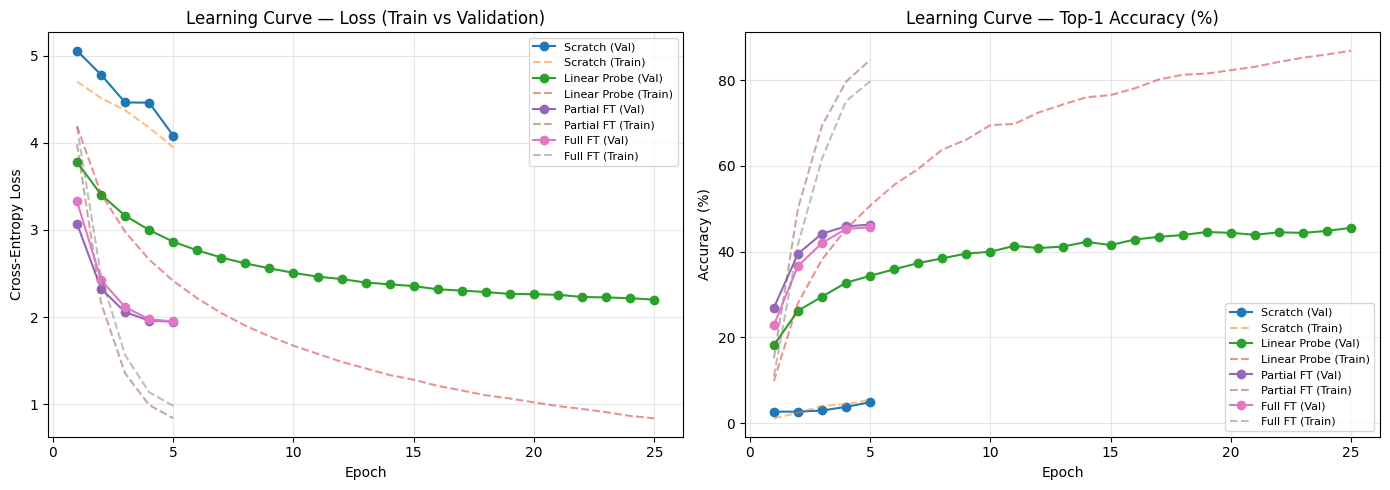


Mô hình tốt nhất trên Validation: 3. Partial FT (5 ep) (Val Top-1: 46.29%)
Đã lưu checkpoint tại: bai6_aircraft_outputs/best_efficientnet_b0_fgvc_aircraft.pt


In [ ]:
df_val = pd.DataFrame(results_summary)
print("=== BẢNG SO SÁNH 4 CHIẾN LƯỢC TRÊN TẬP VALIDATION ===")
display(df_val)

# Vẽ Learning Curves (Val Loss & Val Top-1 Accuracy)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, h in histories.items():
    epochs_axis = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(epochs_axis, h["val_loss"], marker="o", label=f"{name} (Val)")
    axes[0].plot(epochs_axis, h["train_loss"], linestyle="--", alpha=0.5, label=f"{name} (Train)")

    axes[1].plot(epochs_axis, [v * 100 for v in h["val_acc"]], marker="o", label=f"{name} (Val)")
    axes[1].plot(epochs_axis, [v * 100 for v in h["train_acc"]], linestyle="--", alpha=0.5, label=f"{name} (Train)")

axes[0].set_title("Learning Curve — Loss (Train vs Validation)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_title("Learning Curve — Top-1 Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Chọn mô hình tốt nhất chỉ dựa trên Validation Top-1 Accuracy
best_row = df_val.sort_values(by=["Val Top-1 (%)", "Val Macro-F1"], ascending=False).iloc[0]
key_map = {
    "1. Scratch (5 ep)": "Scratch",
    "2. Linear Probe (25 ep)": "Linear Probe",
    "3. Partial FT (5 ep)": "Partial FT",
    "4. Full FT (5 ep)": "Full FT",
}
best_strategy_key = key_map[best_row["Chiến lược"]]
best_model = trained_models[best_strategy_key]

checkpoint_path = OUTPUT_DIR / "best_efficientnet_b0_fgvc_aircraft.pt"
torch.save(
    {
        "strategy": best_row["Chiến lược"],
        "model_state_dict": best_model.state_dict(),
        "num_classes": NUM_CLASSES,
        "class_names": CLASS_NAMES,
        "image_size": IMAGE_SIZE,
        "mean": MEAN,
        "std": STD,
        "val_metrics": best_row.to_dict(),
    },
    checkpoint_path,
)
print(f"\nMô hình tốt nhất trên Validation: {best_row['Chiến lược']} (Val Top-1: {best_row['Val Top-1 (%)']}%)")
print(f"Đã lưu checkpoint tại: {checkpoint_path}")

# Tải lại Checkpoint, đánh giá Test độc lập 1 lần, phân tích lỗi & suy luận

Đã tải lại checkpoint thành công (Chiến lược: 3. Partial FT (5 ep)).

=== KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (3.333 ẢNH) ===
Test Loss     : 1.9659
Test Top-1 Acc: 45.72%
Test Top-5 Acc: 77.26%
Test Macro-F1 : 0.4524

=== TOP CẶP BIẾN THỂ MÁY BAY HAY NHẦM LẪN NHẤT ===


,Nhãn thật,Dự đoán nhầm thành,Số lần nhầm
0,DC-3,C-47,15
1,747-300,747-200,12
2,E-195,E-190,12
3,BAE 146-200,BAE 146-300,12
4,707-320,DC-8,12
5,737-800,E-190,11
6,MD-90,MD-80,11
7,ERJ 135,ERJ 145,11
8,A330-300,A330-200,10
9,CRJ-700,CRJ-900,10


Tổng số ảnh dự đoán sai: 1809 / 3333


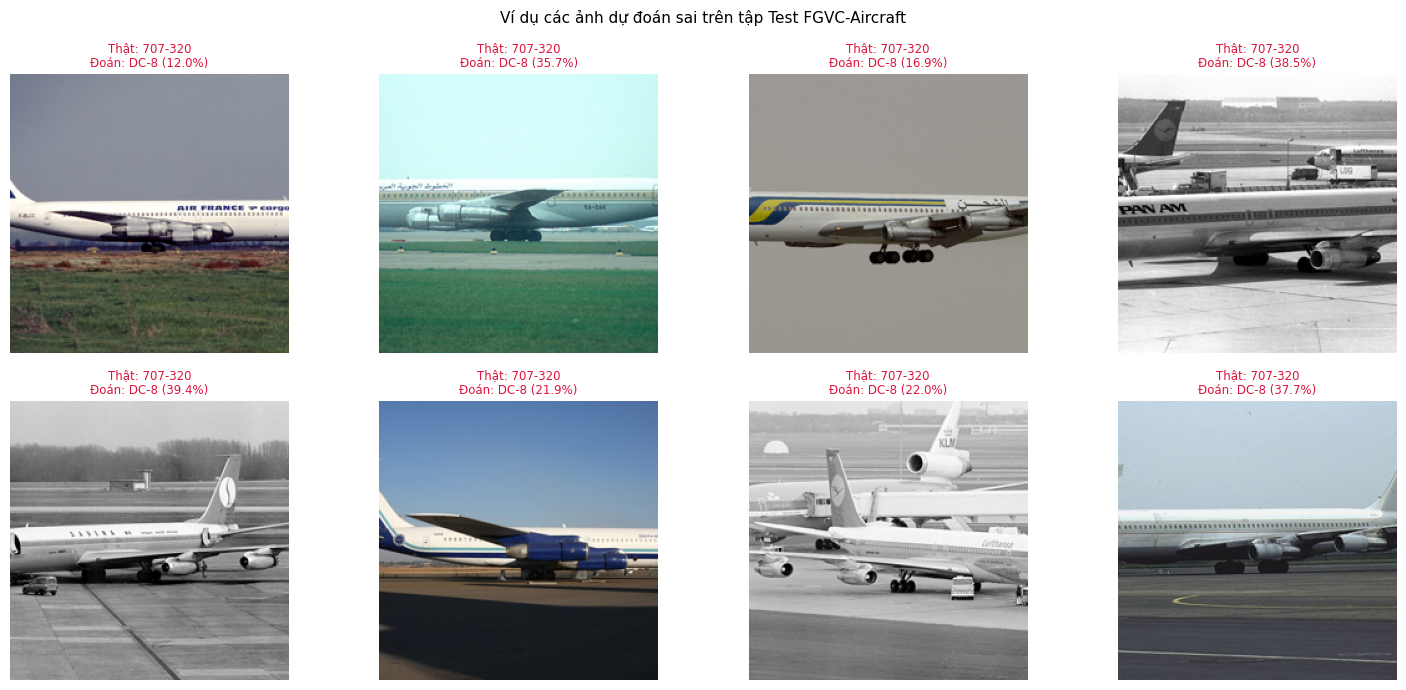

In [ ]:
# 1. Tải lại mô hình từ checkpoint
ckpt = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
loaded_model = build_efficientnet_b0("full", num_classes=ckpt["num_classes"])
loaded_model.load_state_dict(ckpt["model_state_dict"])
loaded_model.eval()
print(f"Đã tải lại checkpoint thành công (Chiến lược: {ckpt['strategy']}).")

# 2. Tải tập Test và đánh giá duy nhất một lần
aircraft_test = datasets.FGVCAircraft(
    DATA_DIR, split="test", annotation_level="variant", download=False, transform=eval_transform
)
test_loader = DataLoader(
    aircraft_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True
)

criterion = nn.CrossEntropyLoss()
test_res = evaluate_model(loaded_model, test_loader, criterion)

print("\n=== KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (3.333 ẢNH) ===")
print(f"Test Loss     : {test_res['loss']:.4f}")
print(f"Test Top-1 Acc: {test_res['top1']*100:.2f}%")
print(f"Test Top-5 Acc: {test_res['top5']*100:.2f}%")
print(f"Test Macro-F1 : {test_res['macro_f1']:.4f}")

# 3. Phân tích các cặp lớp hay nhầm lẫn nhất (Top-10 nhầm lẫn)
cm = confusion_matrix(test_res["y_true"], test_res["y_pred"])
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)

flat_indices = np.argsort(cm_off_diag.ravel())[::-1][:10]
confused_pairs = []
for idx in flat_indices:
    r, c = divmod(idx, NUM_CLASSES)
    if cm_off_diag[r, c] > 0:
        confused_pairs.append({
            "Nhãn thật": CLASS_NAMES[r],
            "Dự đoán nhầm thành": CLASS_NAMES[c],
            "Số lần nhầm": int(cm_off_diag[r, c]),
        })

print("\n=== TOP CẶP BIẾN THỂ MÁY BAY HAY NHẦM LẪN NHẤT ===")
display(pd.DataFrame(confused_pairs))

# 4. Hiển thị 8 ảnh dự đoán sai trên tập Test kèm xác suất dự đoán
wrong_indices = np.where(test_res["y_true"] != test_res["y_pred"])[0]
print(f"Tổng số ảnh dự đoán sai: {len(wrong_indices)} / {len(aircraft_test)}")

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
mean_t = torch.tensor(MEAN).view(3, 1, 1)
std_t = torch.tensor(STD).view(3, 1, 1)

with torch.no_grad():
    for ax, sample_idx in zip(axes.flat, wrong_indices[:8]):
        img_tensor, true_label = aircraft_test[sample_idx]
        probs = torch.softmax(loaded_model(img_tensor.unsqueeze(0).to(DEVICE)), dim=1)[0]
        pred_label = probs.argmax().item()
        conf = probs[pred_label].item() * 100

        img_vis = (img_tensor * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(img_vis)
        ax.set_title(
            f"Thật: {CLASS_NAMES[true_label]}\nĐoán: {CLASS_NAMES[pred_label]} ({conf:.1f}%)",
            fontsize=8.5,
            color="crimson",
        )
        ax.axis("off")

plt.suptitle("Ví dụ các ảnh dự đoán sai trên tập Test FGVC-Aircraft", fontsize=11)
plt.tight_layout()
plt.show()

# Gợi ý phần nhận xét & thảo luận (để viết vào cell Markdown báo cáo)

So sánh 4 chiến lược học:

* Scratch (5 epoch): Độ chính xác rất thấp vì 3.334 ảnh chia cho 100 lớp (~33 ảnh/lớp) quá ít để học từ đầu toàn bộ bộ lọc thị giác trong 5 epoch.

* Linear Probe (25 epoch): Hội tụ rất nhanh nhờ feature caching, đạt kết quả khá tốt nhờ tận dụng đặc trưng tổng quát của ImageNet-1K, nhưng bị giới hạn vì các đặc trưng tầng sâu của ImageNet chưa chuyên biệt cho chi tiết cấu trúc máy bay (domain shift).

* Partial Fine-Tuning & Full Fine-Tuning (5 epoch): Cải thiện rõ rệt so với Linear Probe vì các block sâu của EfficientNet-B0 được điều chỉnh trực tiếp theo đặc trưng phân biệt mịn của máy bay (hình dạng mũi, số lượng động cơ, kiểu cánh đuôi). Việc giữ BatchNorm đóng băng ở .eval() và dùng lr=1e-4 cho backbone giúp tránh hiện tượng phá hủy trọng số gốc (negative transfer / catastrophic forgetting).

Phân tích lỗi sai (Error Analysis): Các cặp nhầm lẫn phổ biến nhất thường rơi vào những biến thể cùng họ máy bay (ví dụ giữa các phiên bản của Boeing 737, Airbus A320/A321, hoặc 747-200/747-400) vốn có ngoại hình gần như giống hệt nhau và chỉ khác ở góc chụp xa hoặc điều kiện ánh sáng